In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Consistent visualization style
sns.set_theme(style="whitegrid", palette="deep")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [3]:
DATA_PATH = Path("../data/raw/ai4i2020.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully: {df.shape[0]:,} rows")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully: 10,000 rows
Number of columns: 14


In [5]:
display(df.head())
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Dataset shape: (10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Data types:


,Data type
UDI,int64
Product ID,str
Type,str
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


In [6]:
missing_summary = pd.DataFrame({
    "Missing count": df.isnull().sum(),
    "Missing percentage": (
        df.isnull().mean() * 100
    ).round(2),
})

display(missing_summary)
print("Duplicate rows:", df.duplicated().sum())

,Missing count,Missing percentage
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


Duplicate rows: 0


In [7]:
TARGET = "Machine failure"

print("Target values:", sorted(df[TARGET].unique()))

print("\nFailure counts:")
display(df[TARGET].value_counts().sort_index())

print("\nFailure percentages:")
display(
    (df[TARGET].value_counts(normalize=True).sort_index() * 100)
    .round(2)
    .rename("Percentage")
)

Target values: [np.int64(0), np.int64(1)]

Failure counts:


Machine failure
0    9661
1     339
Name: count, dtype: int64


Failure percentages:


Machine failure
0    96.61
1     3.39
Name: Percentage, dtype: float64

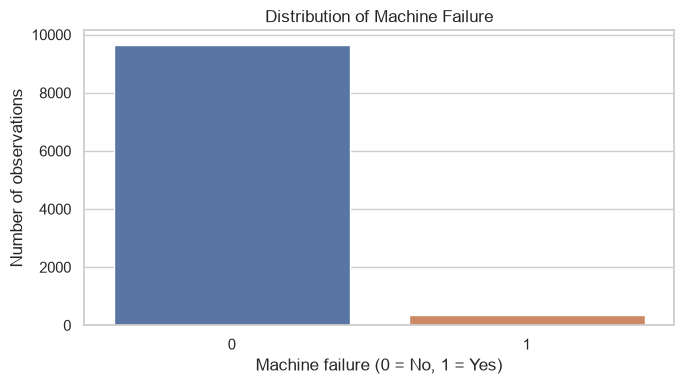

In [8]:
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=df,
    x=TARGET,
    hue=TARGET,
    legend=False,
)

ax.set_title("Distribution of Machine Failure")
ax.set_xlabel("Machine failure (0 = No, 1 = Yes)")
ax.set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

In [9]:
TARGET = "Machine failure"

NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

CATEGORICAL_FEATURES = ["Type"]

FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Input feature shape: (10000, 6)
Target shape: (10000,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


,Failure rate,Observations,Failures,Failure rate (%)
Type,,,,
H,0.02,1003,21,2.09
L,0.04,6000,235,3.92
M,0.03,2997,83,2.77


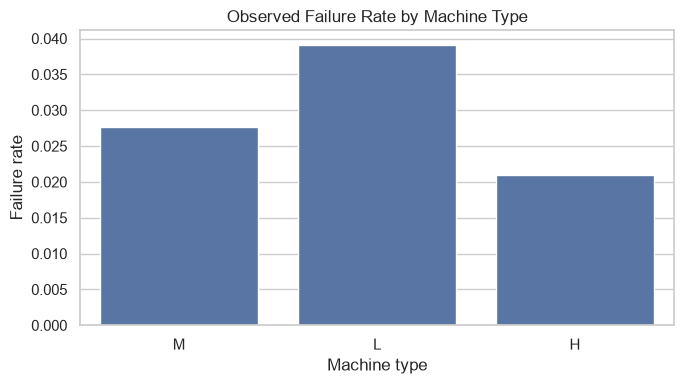

In [11]:
failure_rate_by_type = (
    df.groupby("Type", observed=True)[TARGET]
    .agg(["mean", "count", "sum"])
    .rename(columns={
        "mean": "Failure rate",
        "count": "Observations",
        "sum": "Failures",
    })
)

failure_rate_by_type["Failure rate (%)"] = (
    failure_rate_by_type["Failure rate"] * 100
)

display(failure_rate_by_type.round(2))

plt.figure(figsize=(7, 4))

sns.barplot(
    data=df,
    x="Type",
    y=TARGET,
    estimator="mean",
    errorbar=None,
)

plt.title("Observed Failure Rate by Machine Type")
plt.xlabel("Machine type")
plt.ylabel("Failure rate")
plt.tight_layout()
plt.show()

In [12]:
failure_summary = (
    df.groupby(TARGET)[NUMERIC_FEATURES]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(failure_summary)

Air temperature [K]              Process temperature [K]              Rotational speed [rpm]          \
                               mean median   std                    mean median   std                   mean  median   
Machine failure                                                                                                        
0                            299.97  300.0  1.99                  310.00  310.0  1.49                1540.26  1507.0   
1                            300.89  301.6  2.07                  310.29  310.4  1.36                1496.49  1365.0   

                        Torque [Nm]               Tool wear [min]                
                    std        mean median    std            mean median    std  
Machine failure                                                                  
0                167.39       39.63   39.9   9.47          106.69  107.0  62.95  
1                384.94       50.17   53.7  16.37          143.78  165.0  72.76

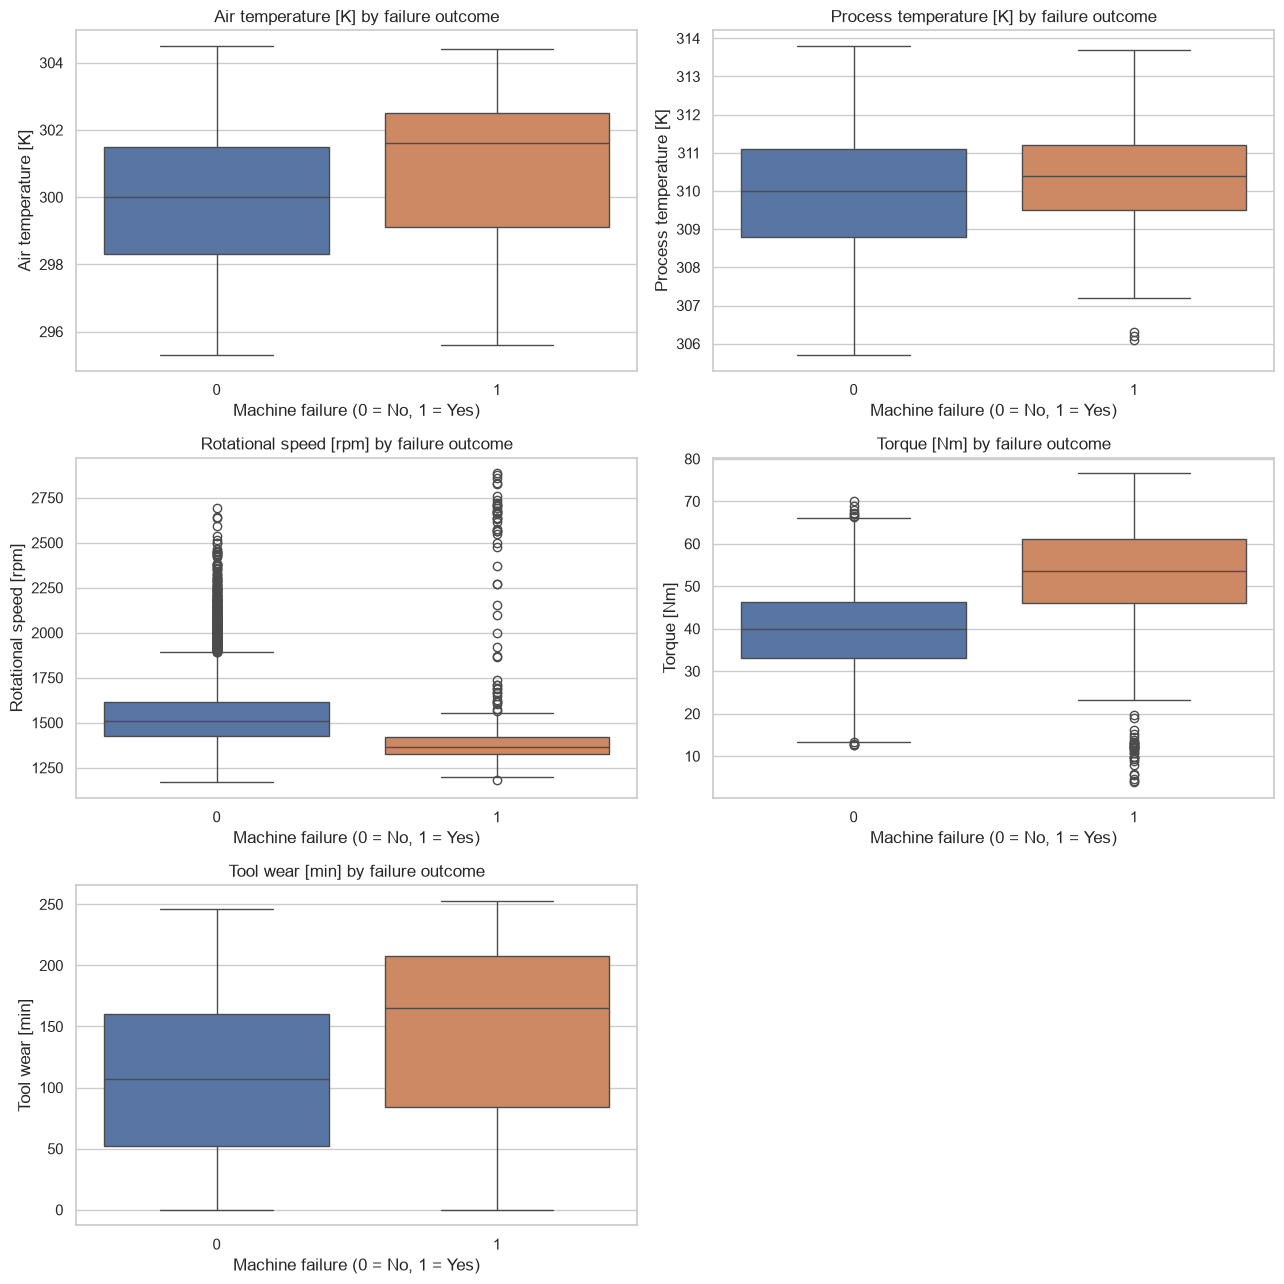

In [13]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(13, 13),
)

axes = axes.flatten()

for i, feature in enumerate(NUMERIC_FEATURES):
    sns.boxplot(
        data=df,
        x=TARGET,
        y=feature,
        hue=TARGET,
        legend=False,
        ax=axes[i],
    )

    axes[i].set_title(f"{feature} by failure outcome")
    axes[i].set_xlabel("Machine failure (0 = No, 1 = Yes)")

axes[-1].axis("off")

plt.tight_layout()
plt.show()

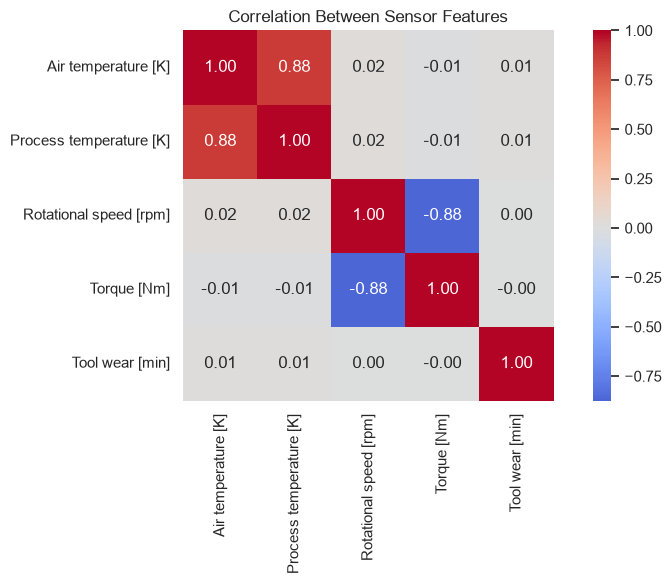

In [14]:
correlation_matrix = df[NUMERIC_FEATURES].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
)

plt.title("Correlation Between Sensor Features")
plt.tight_layout()
plt.show()

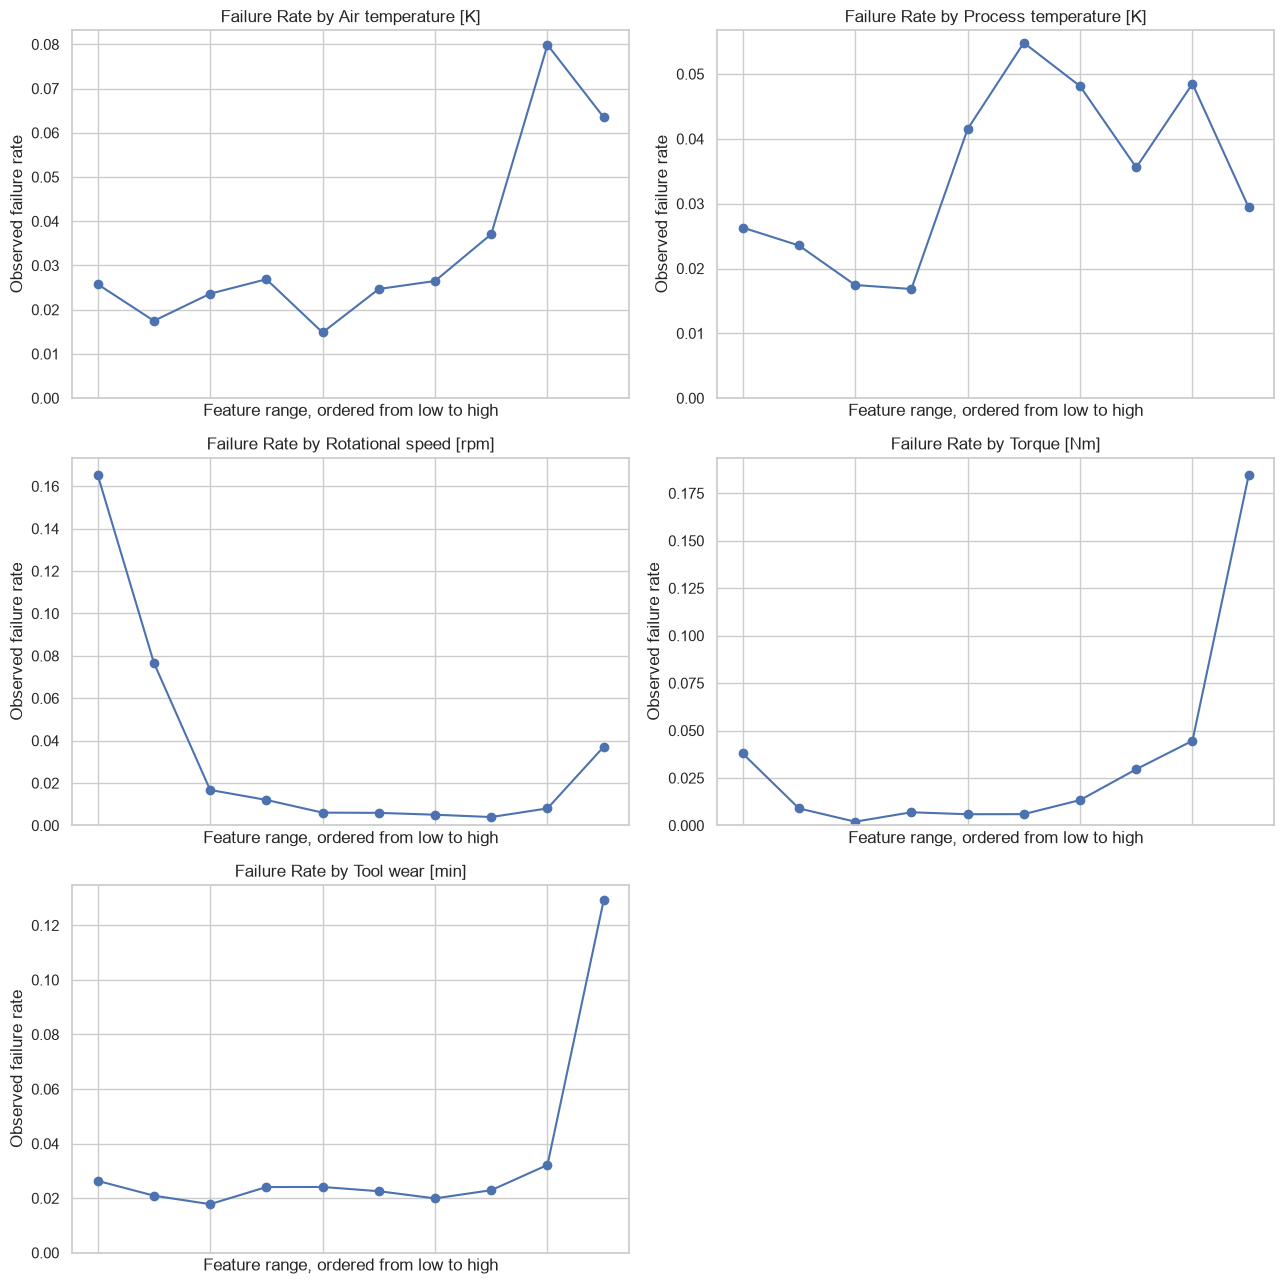

In [15]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(13, 13),
)

axes = axes.flatten()

for i, feature in enumerate(NUMERIC_FEATURES):
    plot_df = df[[feature, TARGET]].copy()

    plot_df["Feature range"] = pd.qcut(
        plot_df[feature],
        q=10,
        duplicates="drop",
    )

    rates = (
        plot_df.groupby("Feature range", observed=True)[TARGET]
        .mean()
    )

    axes[i].plot(
        range(len(rates)),
        rates.values,
        marker="o",
    )

    axes[i].set_title(f"Failure Rate by {feature}")
    axes[i].set_xlabel("Feature range, ordered from low to high")
    axes[i].set_ylabel("Observed failure rate")
    axes[i].set_ylim(bottom=0)
    axes[i].tick_params(axis="x", labelbottom=False)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            CATEGORICAL_FEATURES,
        ),
        (
            "numerical",
            StandardScaler(),
            NUMERIC_FEATURES,
        ),
    ],
    remainder="drop",
)

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (8000, 6)
Testing features: (2000, 6)

Training target: (8000,)
Testing target: (2000,)


In [19]:
distribution = pd.DataFrame({
    "Full dataset (%)": y.value_counts(normalize=True) * 100,
    "Training set (%)": y_train.value_counts(normalize=True) * 100,
    "Testing set (%)": y_test.value_counts(normalize=True) * 100,
}).sort_index()

display(distribution.round(2))

,Full dataset (%),Training set (%),Testing set (%)
Machine failure,,,
0,96.61,96.61,96.6
1,3.39,3.39,3.4


In [20]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8000, 8)
Processed testing shape: (2000, 8)


In [21]:
feature_names = preprocessor.get_feature_names_out()

print("Transformed feature names:")
print(feature_names.tolist())

Transformed feature names:
['categorical__Type_H', 'categorical__Type_L', 'categorical__Type_M', 'numerical__Air temperature [K]', 'numerical__Process temperature [K]', 'numerical__Rotational speed [rpm]', 'numerical__Torque [Nm]', 'numerical__Tool wear [min]']


In [22]:
processed_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names,
    index=X_train.index,
)

display(processed_df.head())

,categorical__Type_H,categorical__Type_L,categorical__Type_M,numerical__Air temperature [K],numerical__Process temperature [K],numerical__Rotational speed [rpm],numerical__Torque [Nm],numerical__Tool wear [min]
4058,0.0,0.0,1.0,0.998914,0.604282,-0.460607,0.718305,-0.843997
1221,0.0,0.0,1.0,-1.505194,-1.153260,-0.775574,0.638456,0.382263
6895,0.0,0.0,1.0,0.498092,1.077466,-1.007654,0.558607,0.460870
9863,0.0,1.0,0.0,-0.553633,-0.139294,-0.709265,1.626586,-0.372359
8711,0.0,1.0,0.0,-1.455112,-1.018064,1.070019,-1.128202,-0.906882


In [23]:
assert len(X_train) + len(X_test) == len(X)
assert len(y_train) == len(X_train)
assert len(y_test) == len(X_test)

assert set(y_train.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

assert not X_train.isnull().any().any()
assert not X_test.isnull().any().any()

print("All initial data preparation checks passed.")
print(f"Training observations: {len(X_train):,}")
print(f"Testing observations: {len(X_test):,}")
print(f"Training failure rate: {y_train.mean():.2%}")
print(f"Testing failure rate: {y_test.mean():.2%}")

All initial data preparation checks passed.
Training observations: 8,000
Testing observations: 2,000
Training failure rate: 3.39%
Testing failure rate: 3.40%
